In [19]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))
 
module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils.ds_helper import get_dataset_distribution
from src.utils.confusion_matrix import generate_confusion
from src.utils.roc_curve import generate_roc_curve


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [20]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC102.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data02", "train")
test_data_dir = os.path.join(dataset_path, "data02", "test")
val_data_dir = os.path.join(dataset_path, "data02", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data02/train
/Users/joshan/Documents/final-year-project/dataset/data02/test
/Users/joshan/Documents/final-year-project/dataset/data02/val


In [18]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     4667 │        3633 │           3573 │      1155 │   13028 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 4667,
  'PNEUMONIA': 3633,
  'TUBERCULOSIS': 3573,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-05-07 08:48:32.046143: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-05-07 08:48:32.046214: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-07 08:48:32.046231: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-07 08:48:32.046591: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-07 08:48:32.046618: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [15]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(192, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.4), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(3, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
import keras


# Define the early stopping monitor
# This stops training if 'val_loss' doesn't improve for 3 epochs
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-03-02 10:28:20.080708: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


372/372 ━━━━━━━━━━━━━━━━━━━━ 60s 158ms/step - accuracy: 0.6450 - loss: 1.2249 - val_accuracy: 0.8530 - val_loss: 0.4757
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 63s 169ms/step - accuracy: 0.7778 - loss: 1.0141 - val_accuracy: 0.8833 - val_loss: 0.3990
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 54s 145ms/step - accuracy: 0.8041 - loss: 0.9825 - val_accuracy: 0.8991 - val_loss: 0.3787
Epoch 4/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 51s 138ms/step - accuracy: 0.8189 - loss: 1.0065 - val_accuracy: 0.8833 - val_loss: 0.4692
Epoch 5/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 55s 147ms/step - accuracy: 0.8204 - loss: 1.2282 - val_accuracy: 0.9107 - val_loss: 0.5624
Epoch 6/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 60s 160ms/step - accuracy: 0.8369 - loss: 1.3483 - val_accuracy: 0.9135 - val_loss: 0.5132
Epoch 7/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 59s 159ms/step - accuracy: 0.8468 - loss: 1.2951 - val_accuracy: 0.9236 - val_loss: 0.5843
Epoch 8/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 55s 146ms/step - accuracy: 0.8505 - loss: 1.4476 - val

In [6]:
# Save the model
model.save('CXC102.keras')
print("Model saved successfully!")

Model saved successfully!


In [16]:
model = tf.keras.models.load_model('CXC102.keras')

In [45]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

2026-05-07 08:48:43.244973: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9234 - loss: 2.5557
Test Loss: 2.555711269378662
Test Accuracy: 92.34%


In [17]:
# evaluated against validation dataset
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.9198 - loss: 3.9177
Test Loss: 3.917724609375
Test Accuracy: 91.98%


2026-05-07 08:48:52.341873: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


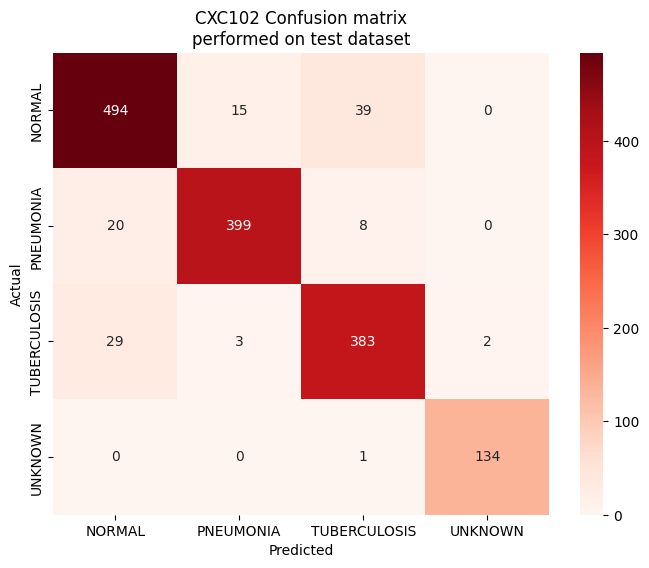

              precision    recall  f1-score   support

      NORMAL       0.91      0.90      0.91       548
   PNEUMONIA       0.96      0.93      0.95       427
TUBERCULOSIS       0.89      0.92      0.90       417
     UNKNOWN       0.99      0.99      0.99       135

    accuracy                           0.92      1527
   macro avg       0.94      0.94      0.94      1527
weighted avg       0.92      0.92      0.92      1527



In [10]:
generate_confusion(
    test_ds, 
    model= model, 
    title= "CXC102 Confusion matrix", 
    subtitle= "performed on test dataset"
)

2026-05-07 08:50:37.961037: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


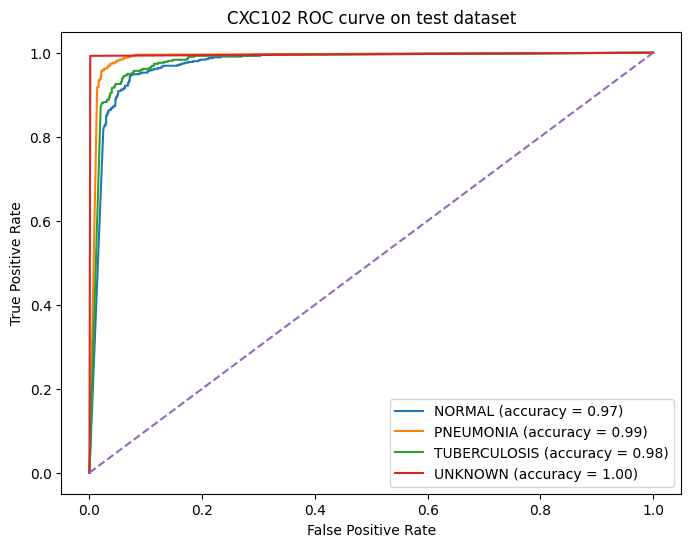

In [13]:
generate_roc_curve(
    test_ds,
    model=model, 
    title="CXC102 ROC curve on test dataset"
    )

2026-05-07 08:49:24.430419: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


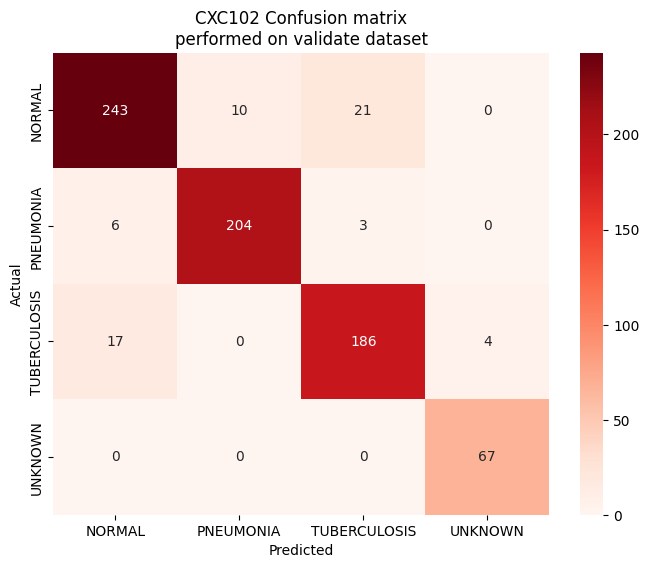

              precision    recall  f1-score   support

      NORMAL       0.91      0.89      0.90       274
   PNEUMONIA       0.95      0.96      0.96       213
TUBERCULOSIS       0.89      0.90      0.89       207
     UNKNOWN       0.94      1.00      0.97        67

    accuracy                           0.92       761
   macro avg       0.92      0.94      0.93       761
weighted avg       0.92      0.92      0.92       761



In [12]:
generate_confusion(
    val_ds, 
    model= model, 
    title= "CXC102 Confusion matrix", 
    subtitle= "performed on validate dataset"
)

2026-05-07 08:51:05.553475: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


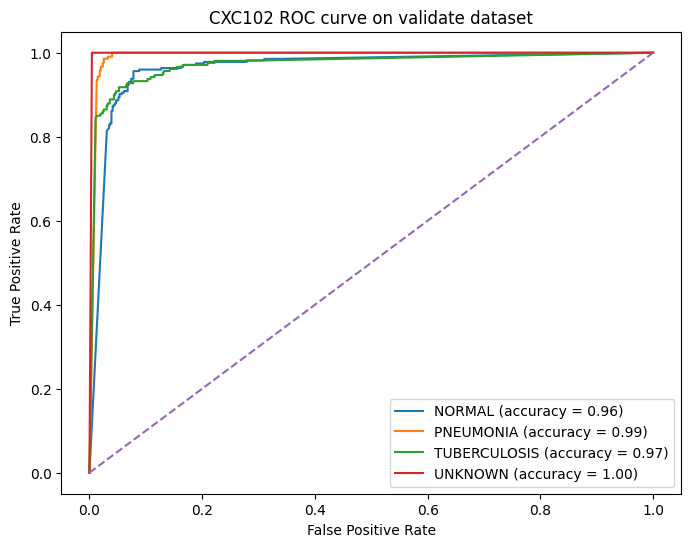

In [14]:
generate_roc_curve(
    val_ds,
    model=model, 
    title="CXC102 ROC curve on validate dataset"
    )

In [16]:
# model_path = os.getenv("MODEL_DIR")
model = os.path.join("CXC102.keras")
print(model)
model = tf.keras.models.load_model(model)


CXC102.keras


In [17]:
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9102 - loss: 0.8837
Test Loss: 0.8837059140205383
Test Accuracy: 91.02%


In [18]:
# model_path = os.getenv("MODEL_DIR")
model = os.path.join(model_path, "CXC1.keras")
print(model)
model = tf.keras.models.load_model(model)


/Users/joshan/Documents/final-year-project/models/CXC/CXC1.keras


In [19]:
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9045 - loss: 5.7636
Test Loss: 5.763561248779297
Test Accuracy: 90.45%


In [21]:
import numpy as np
from tensorflow.keras.preprocessing import image

def test_image(path):
    # 1. Load the image and resize it to match your model's input_shape
    img = image.load_img(path, target_size=(224, 224))
    
    # 2. Convert the image to a numpy array
    img_array = image.img_to_array(img)
    
    # 3. Expand dimensions to create a "batch" of one: (1, 224, 224, 3)
    img_batch = np.expand_dims(img_array, axis=0)
    
    # 4. Predict
    predictions = model.predict(img_batch)
    
    # 5. Print the raw probability scores
    print(f"Predictions for {path}:")
    print(predictions)
    
    # Optional: Print the class with the highest probability
    class_idx = np.argmax(predictions[0])
    conf_score = np.max(predictions[0]) * 100
    print(f"Detected Class: {class_idx} ({conf_score:.2f}% confidence)")

# Example usage:
# test_image('path_to_your_test_image.jpg')

In [24]:
test_image('/Users/joshan/Desktop/sdfsds.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predictions for /Users/joshan/Desktop/sdfsds.jpg:
[[1. 0. 0.]]
Detected Class: 0 (100.00% confidence)
